In [2]:
import pandas as pd
df = pd.read_csv("Hydrogen_Uncertainty_dataset.csv")

In [3]:
df

,"Natural Gas Cost ($/MMBtu, HHV)",Absorber CO2 Removal Efficiency (%),Capacity Factor (%),Performance Parameter: Annual Operating Hours (hours),Performance Parameter: Annual H2 Production (million tonne/yr),Performance Parameter: Annual CO2 Captured (million tonne/yr),Hydrogen Production Cost: Total Cost: Levelized Cost ($/lb H2),Variable O&M Cost: CO2 T&S: O&M Cost ($/lb H2),CO2 Captured (tons/hr),Cost of CO2 Captured ($/ton)
0,7.975000,96.3675,76.5375,6709.276855,0.125799,1.284130,1.184908,0.065090,210.978004,232.157446
1,10.424999,95.7825,73.5625,6448.488770,0.120909,1.231241,1.412497,0.064933,210.469291,277.417550
2,7.825000,97.4025,92.6375,8120.603027,0.152261,1.560883,1.118635,0.065368,211.877999,218.241634
3,3.325000,94.2075,61.4875,5389.994141,0.101062,1.022440,0.850518,0.064511,209.099729,168.137687
4,8.525001,90.3375,84.0625,7368.918945,0.138167,1.375331,1.198089,0.063472,205.734506,240.722633
...,...,...,...,...,...,...,...,...,...,...
195,2.425000,96.4575,84.5875,7414.940430,0.139030,1.419718,0.666642,0.065114,211.056248,130.565850
196,7.675000,94.7475,87.5625,7675.728516,0.143920,1.459296,1.117000,0.064655,209.569287,220.323344
197,4.275000,98.7075,87.0375,7629.707031,0.143057,1.474381,0.828909,0.065718,213.012786,160.855549
198,2.675000,94.4775,66.9125,5865.549316,0.109979,1.113899,0.761790,0.064583,209.334506,150.428225


In [4]:
df.isna().sum()

Natural Gas Cost ($/MMBtu, HHV)                                   0
Absorber CO2 Removal Efficiency (%)                               0
Capacity Factor (%)                                               0
Performance Parameter: Annual Operating Hours (hours)             0
Performance Parameter: Annual H2 Production (million tonne/yr)    0
Performance Parameter: Annual CO2 Captured (million tonne/yr)     0
Hydrogen Production Cost: Total Cost: Levelized Cost ($/lb H2)    0
Variable O&M Cost: CO2 T&S: O&M Cost ($/lb H2)                    0
CO2 Captured (tons/hr)                                            0
Cost of CO2 Captured ($/ton)                                      0
dtype: int64

In [5]:
df.duplicated().sum()

np.int64(0)

In [6]:
x = df[['Natural Gas Cost ($/MMBtu, HHV)',
    'Absorber CO2 Removal Efficiency (%)',
    'Capacity Factor (%)']]

y = df['CO2 Captured (tons/hr)']

In [7]:
x

,"Natural Gas Cost ($/MMBtu, HHV)",Absorber CO2 Removal Efficiency (%),Capacity Factor (%)
0,7.975000,96.3675,76.5375
1,10.424999,95.7825,73.5625
2,7.825000,97.4025,92.6375
3,3.325000,94.2075,61.4875
4,8.525001,90.3375,84.0625
...,...,...,...
195,2.425000,96.4575,84.5875
196,7.675000,94.7475,87.5625
197,4.275000,98.7075,87.0375
198,2.675000,94.4775,66.9125


In [8]:
y

0      210.978004
1      210.469291
2      211.877999
3      209.099729
4      205.734506
          ...    
195    211.056248
196    209.569287
197    213.012786
198    209.334506
199    206.321480
Name: CO2 Captured (tons/hr), Length: 200, dtype: float64

In [9]:
from sklearn.model_selection import GridSearchCV, train_test_split, RandomizedSearchCV
from sklearn.linear_model import LinearRegression
from sklearn.svm import SVR
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from xgboost import XGBRegressor
from sklearn.ensemble import GradientBoostingRegressor

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

print("\n=== SHAP MODEL ===\n")


=== SHAP MODEL ===



In [10]:
# Gradient Boosting Regressor
gbr_grid = GridSearchCV(
    GradientBoostingRegressor(random_state=42),
    {
        "n_estimators": [100, 300],
        "max_depth": [3, 6, 10],
        "learning_rate": [0.01, 0.1, 0.3],
        "subsample": [0.8, 1.0],
        "max_features": [0.8, 1.0]
    },
    cv=5, scoring="r2", n_jobs=-1
)
gbr_grid.fit(x_train, y_train)

best_gbr = gbr_grid.best_estimator_
print("Gradient Boosting best params:", gbr_grid.best_params_)
print('Train R2:', best_gbr.score(x_train, y_train))
print('Test R2:', best_gbr.score(x_test, y_test))

Gradient Boosting best params: {'learning_rate': 0.1, 'max_depth': 3, 'max_features': 1.0, 'n_estimators': 100, 'subsample': 0.8}
Train R2: 0.9999805498051919
Test R2: 0.9996481156116822


In [11]:
#Checking the RMSE and MAPE scores
from sklearn.metrics import mean_squared_error
import numpy as np

print("\n=== RMSE & MAPE ===\n")

models = {
    'Gradient Boost':    best_gbr
}

for name, model in models.items():
    y_pred = model.predict(x_test)
    rmse   = np.sqrt(mean_squared_error(y_test, y_pred))
    mape   = np.mean(np.abs((y_test - y_pred) / y_test)) * 100
    print(f"{name} | RMSE: {rmse:.4f} | MAPE: {mape:.4f}%")


=== RMSE & MAPE ===

Gradient Boost | RMSE: 0.0426 | MAPE: 0.0180%


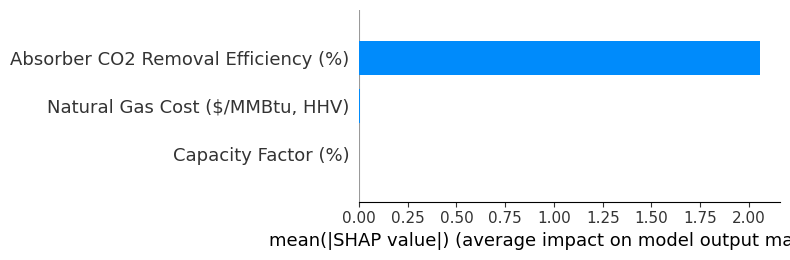

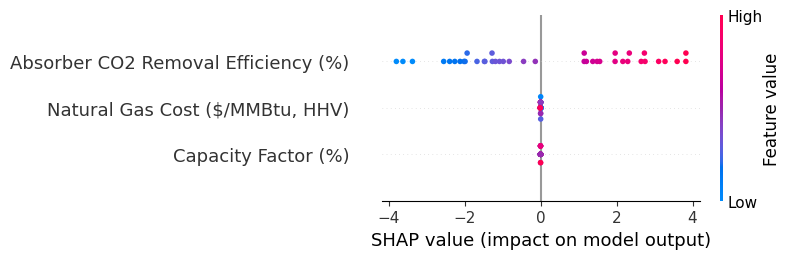

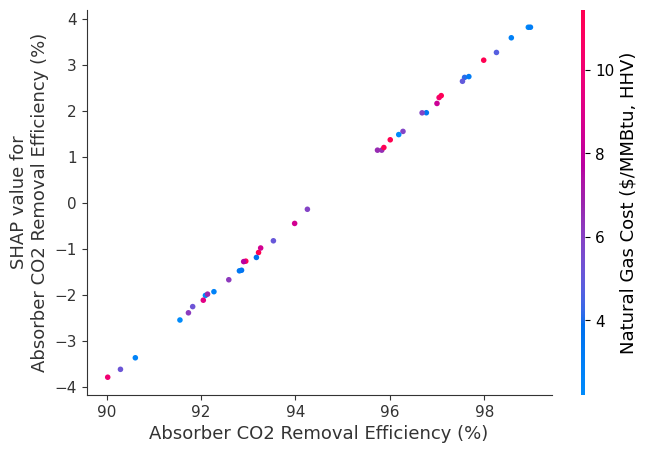

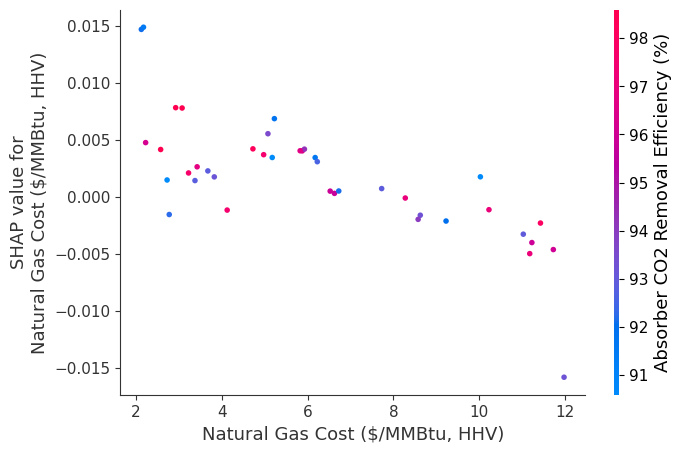

In [12]:
import shap, numpy as np
explainer   = shap.TreeExplainer(best_gbr)
shap_values = explainer.shap_values(x_test)

shap.summary_plot(shap_values, x_test, plot_type="bar")
shap.summary_plot(shap_values, x_test)

mean_abs = np.abs(shap_values).mean(axis=0)
order    = np.argsort(mean_abs)[::-1]
for i in order[:2]:
    shap.dependence_plot(x_test.columns[i], shap_values, x_test)